***Import packages***

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

***Membership Data***

In [2]:
#Loading the data

membership = pd.read_parquet("data/parquet/members_v3.parquet")

In [3]:
membership.duplicated().sum()

np.int64(0)

In [4]:
membership.head()

,msno,city,bd,gender,registered_via,registration_init_time
0,Rb9UwLQTrxzBVwCB6+bCcSQWZ9JiNLC9dXtM1oEsZA8=,1,0,NaN,11,20110911
1,+tJonkh+O1CA796Fm5X60UMOtB6POHAwPjbTRVl/EuU=,1,0,NaN,7,20110914
2,cV358ssn7a0f7jZOwGNWS07wCKVqxyiImJUX6xcIwKw=,1,0,NaN,11,20110915
3,9bzDeJP6sQodK73K5CBlJ6fgIQzPeLnRl0p5B77XP+g=,1,0,NaN,11,20110915
4,WFLY3s7z4EZsieHCt63XrsdtfTEmJ+2PnnKLH5GY4Tk=,6,32,female,9,20110915


In [6]:
membership.info()

<class 'pandas.DataFrame'>
RangeIndex: 6769473 entries, 0 to 6769472
Data columns (total 6 columns):
 #   Column                  Dtype
---  ------                  -----
 0   msno                    str  
 1   city                    int64
 2   bd                      int64
 3   gender                  str  
 4   registered_via          int64
 5   registration_init_time  int64
dtypes: int64(4), str(2)
memory usage: 605.9 MB


In [7]:
dtypes = {
    "msno": "string",
    "city": "int8",
    "bd": "int16",
    "gender": "category",
    "registered_via": "int8"
}
membership = membership.astype(dtypes)

In [8]:
membership.info()

<class 'pandas.DataFrame'>
RangeIndex: 6769473 entries, 0 to 6769472
Data columns (total 6 columns):
 #   Column                  Dtype   
---  ------                  -----   
 0   msno                    string  
 1   city                    int8    
 2   bd                      int16   
 3   gender                  category
 4   registered_via          int8    
 5   registration_init_time  int64   
dtypes: category(1), int16(1), int64(1), int8(2), string(1)
memory usage: 419.6 MB


In [9]:
round(membership.describe(), 2)

,city,bd,registered_via,registration_init_time
count,6769473.00,6769473.00,6769473.00,6769473.00
mean,3.85,9.80,5.25,20145175.91
std,5.48,17.93,2.36,23186.01
min,1.00,-7168.00,-1.00,20040326.00
25%,1.00,0.00,4.00,20140422.00
50%,1.00,0.00,4.00,20151010.00
75%,4.00,21.00,7.00,20160604.00
max,22.00,2016.00,19.00,20170429.00


In [10]:
pd.DataFrame({'%missing_values': round(membership.isnull().sum() / len(membership) * 100, 2)})

,%missing_values
msno,0.00
city,0.00
bd,0.00
gender,65.43
registered_via,0.00
registration_init_time,0.00


In [11]:
#Shape of the data and unique users in membership data
print(f"Shape of membership data: {membership.shape}")
print(f"No. of unique users in membership data: {membership['msno'].nunique()}")

Shape of membership data: (6769473, 6)
No. of unique users in membership data: 6769473


In [12]:
membership['city'].value_counts()

city
1     4804326
5      385069
13     320978
4      246848
22     210407
15     190213
6      135200
14      89940
12      66843
9       47639
11      47489
8       45975
18      38039
10      32482
21      30837
17      27772
3       27282
7       11610
16       5092
20       4233
19       1199
Name: count, dtype: int64

In [13]:
membership['city'].nunique()

21

In [14]:
membership['gender'].value_counts()

gender
male      1195355
female    1144613
Name: count, dtype: int64

In [15]:
membership['gender'].nunique()

2

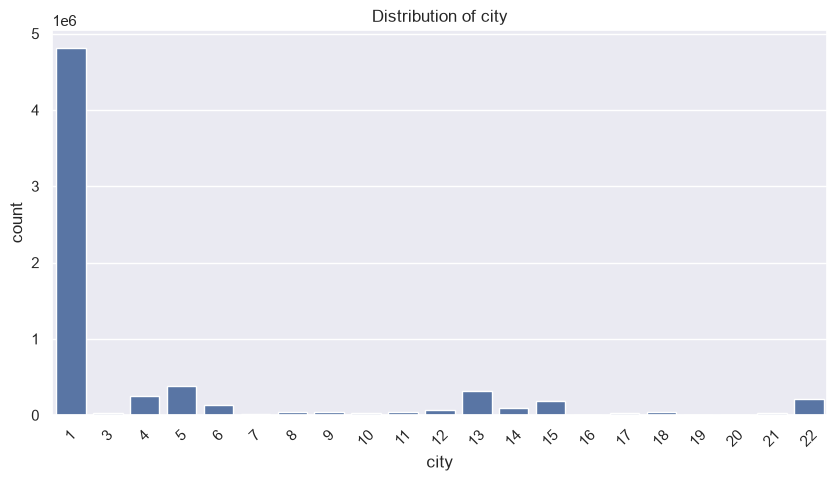

In [16]:
sns.set_theme(style="darkgrid")
plt.figure(figsize=(10, 5))
sns.countplot(data=membership, x=membership['city'])
plt.title(f'Distribution of city')
plt.xticks(rotation=45)
plt.show()

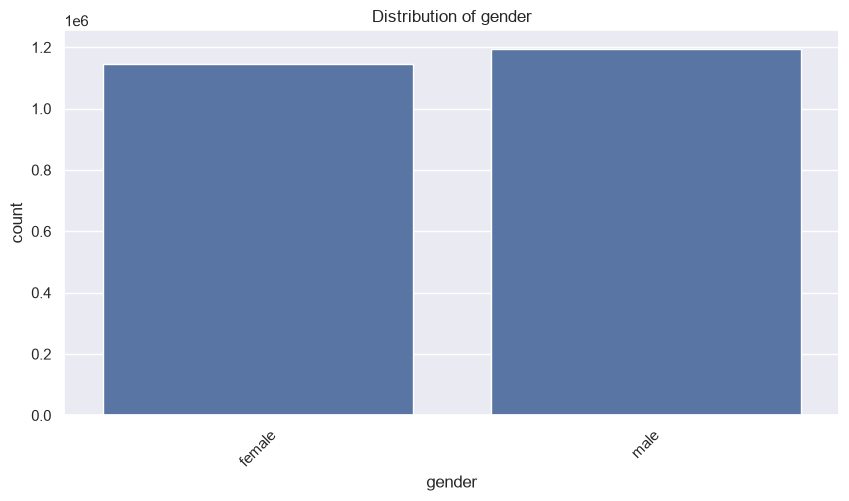

In [17]:
sns.set_theme(style="darkgrid")
plt.figure(figsize=(10, 5))
sns.countplot(data=membership, x=membership['gender'])
plt.title(f'Distribution of gender')
plt.xticks(rotation=45)
plt.show()

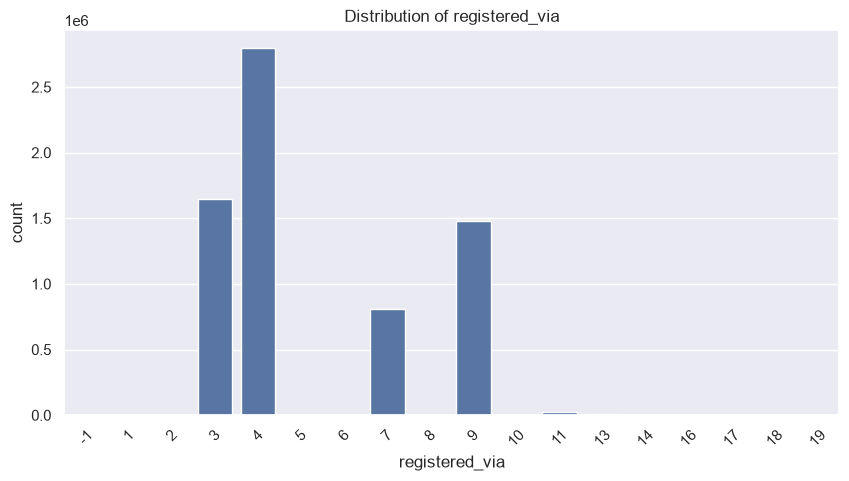

In [18]:
sns.set_theme(style="darkgrid")
plt.figure(figsize=(10, 5))
sns.countplot(data=membership, x=membership['registered_via'])
plt.title(f'Distribution of registered_via')
plt.xticks(rotation=45)
plt.show()

<Axes: >

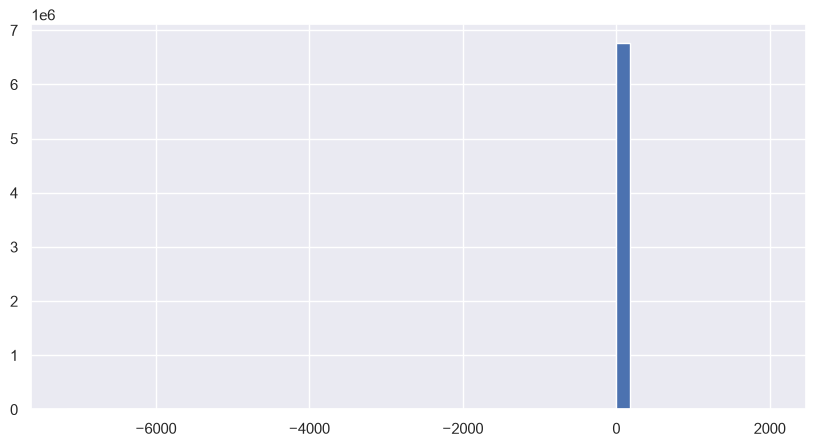

In [19]:
plt.figure(figsize=(10, 5))
membership['bd'].hist(bins=50)

<Axes: xlabel='bd'>

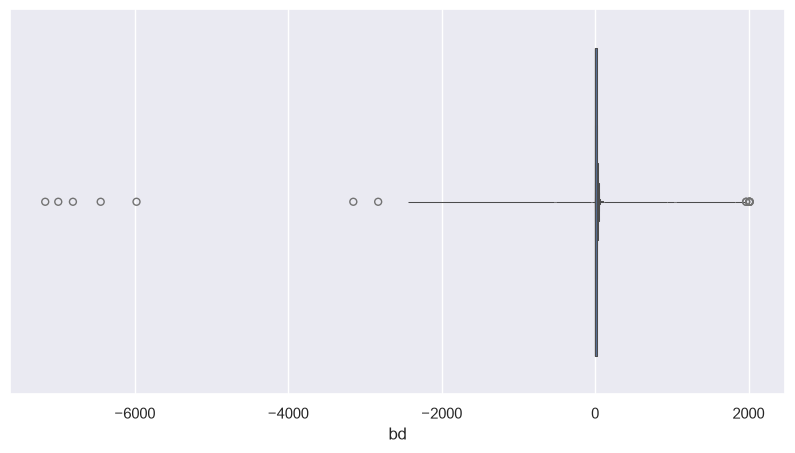

In [20]:
plt.figure(figsize=(10, 5))
sns.boxenplot(data=membership, x='bd')

In [22]:
membership['gender'] = membership['gender'].cat.add_categories(['unknown']).fillna('unknown')


In [23]:
membership.registration_init_time = membership.registration_init_time.astype('str')
membership.registration_init_time = pd.to_datetime(membership.registration_init_time, format='%Y%m%d', errors='coerce')

In [24]:
membership.info()

<class 'pandas.DataFrame'>
RangeIndex: 6769473 entries, 0 to 6769472
Data columns (total 6 columns):
 #   Column                  Dtype         
---  ------                  -----         
 0   msno                    string        
 1   city                    int8          
 2   bd                      int16         
 3   gender                  category      
 4   registered_via          int8          
 5   registration_init_time  datetime64[us]
dtypes: category(1), datetime64[us](1), int16(1), int8(2), string(1)
memory usage: 419.6 MB


In [25]:
membership.registration_init_time

0         2011-09-11
1         2011-09-14
2         2011-09-15
3         2011-09-15
4         2011-09-15
             ...    
6769468   2016-10-20
6769469   2016-10-20
6769470   2016-10-20
6769471   2016-10-20
6769472   2016-10-20
Name: registration_init_time, Length: 6769473, dtype: datetime64[us]

In [26]:
membership.to_parquet("data/interim/members_cleaned.parquet", index=False)

***Transactions Data***

In [3]:
t = pd.read_parquet("data/parquet/transactions.parquet")
t_v2 = pd.read_parquet("data/parquet/transactions_v2.parquet")

In [4]:
transaction = pd.concat([t, t_v2], ignore_index=True, axis=0, sort=False).drop_duplicates()

In [5]:
transaction.duplicated().sum()

np.int64(0)

In [33]:
transaction.head()

,msno,payment_method_id,payment_plan_days,plan_list_price,actual_amount_paid,is_auto_renew,transaction_date,membership_expire_date,is_cancel
0,YyO+tlZtAXYXoZhNr3Vg3+dfVQvrBVGO8j1mfqe4ZHc=,41,30,129,129,1,20150930,20151101,0
1,AZtu6Wl0gPojrEQYB8Q3vBSmE2wnZ3hi1FbK1rQQ0A4=,41,30,149,149,1,20150930,20151031,0
2,UkDFI97Qb6+s2LWcijVVv4rMAsORbVDT2wNXF0aVbns=,41,30,129,129,1,20150930,20160427,0
3,M1C56ijxozNaGD0t2h68PnH2xtx5iO5iR2MVYQB6nBI=,39,30,149,149,1,20150930,20151128,0
4,yvj6zyBUaqdbUQSrKsrZ+xNDVM62knauSZJzakS9OW4=,39,30,149,149,1,20150930,20151121,0


In [34]:
transaction.info()

<class 'pandas.DataFrame'>
Index: 22975416 entries, 0 to 22978754
Data columns (total 9 columns):
 #   Column                  Dtype
---  ------                  -----
 0   msno                    str  
 1   payment_method_id       int64
 2   payment_plan_days       int64
 3   plan_list_price         int64
 4   actual_amount_paid      int64
 5   is_auto_renew           int64
 6   transaction_date        int64
 7   membership_expire_date  int64
 8   is_cancel               int64
dtypes: int64(8), str(1)
memory usage: 2.7 GB


In [35]:
#Shape of the data and unique users in transaction data
print(f"Shape of transaction data: {transaction.shape}")
print(f"No. of unique users: {transaction['msno'].nunique()}")

Shape of transaction data: (22975416, 9)
No. of unique users: 2426143


In [36]:
transaction['payment_method_id'].value_counts()

payment_method_id
41    12219879
40     2308019
38     1819465
39     1603775
37     1048103
36      945953
34      762638
35      551141
33      427879
31      263939
32      247463
30      182135
29      138822
28       99185
27       64599
23       45105
20       34929
19       34209
22       29693
21       24729
18       16886
24       16200
14       14293
25       13785
16       12906
13       11621
17        9969
15        9184
12        6692
26        5259
11        2208
10        1366
7         1089
8          836
6          652
5          475
3          252
2           56
4           15
1           12
Name: count, dtype: int64

In [37]:
transaction['payment_method_id'].nunique()

40

In [38]:
transaction['payment_plan_days'].value_counts()

payment_plan_days
30     20170971
0        872339
31       766610
7        589790
410      162236
195      138802
180       76172
10        38632
90        31440
100       28252
395       20543
120       13619
60        10301
360       10144
200        8946
14         6447
1          5435
240        4528
365        4150
400        3673
415        3299
450        3033
270        1187
45         1123
21          880
35          854
70          636
80          385
99          339
110         179
66          175
230         138
3            68
2            67
15           21
425           1
95            1
Name: count, dtype: int64

In [39]:
transaction['payment_plan_days'].nunique()

37

In [40]:
transaction['plan_list_price'].value_counts()

plan_list_price
149     13130541
99       5258678
0        1516937
129      1197394
180       798173
150       385000
1788      164029
894       139556
100       123931
536        61841
119        32807
480        26834
1599       26190
477        18738
1200       13089
298        11321
300        10610
447         8389
930         7878
35          7732
799         7698
120         6096
134         3852
1299        3052
699         3041
600         2732
450         1719
500         1426
50          1053
1000        1053
350          636
124          598
131          398
400          385
105          359
70           261
2000         248
143          147
126          145
1            138
1150         138
1399         137
596          136
210           89
10            67
15            51
265           25
1260          25
1520          13
800           11
30             7
1300           6
760            3
1825           2
44             1
Name: count, dtype: int64

In [41]:
transaction['plan_list_price'].nunique()

55

In [42]:
transaction['plan_list_price'].value_counts().index

Index([ 149,   99,    0,  129,  180,  150, 1788,  894,  100,  536,  119,  480,
       1599,  477, 1200,  298,  300,  447,  930,   35,  799,  120,  134, 1299,
        699,  600,  450,  500,   50, 1000,  350,  124,  131,  400,  105,   70,
       2000,  143,  126,    1, 1150, 1399,  596,  210,   10,   15,  265, 1260,
       1520,  800,   30, 1300,  760, 1825,   44],
      dtype='int64', name='plan_list_price')

In [43]:
pd.DataFrame({'%missing_values': round(transaction.isnull().sum() / len(transaction) * 100, 2)})

,%missing_values
msno,0.0
payment_method_id,0.0
payment_plan_days,0.0
plan_list_price,0.0
actual_amount_paid,0.0
is_auto_renew,0.0
transaction_date,0.0
membership_expire_date,0.0
is_cancel,0.0


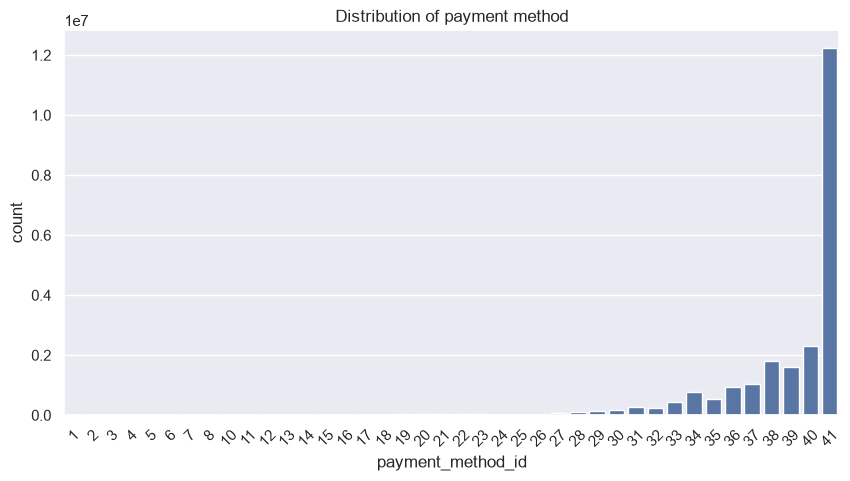

In [44]:
sns.set_theme(style="darkgrid")
plt.figure(figsize=(10, 5))
sns.countplot(data=transaction, x=transaction['payment_method_id'])
plt.title(f'Distribution of payment method')
plt.xticks(rotation=45)
plt.show()

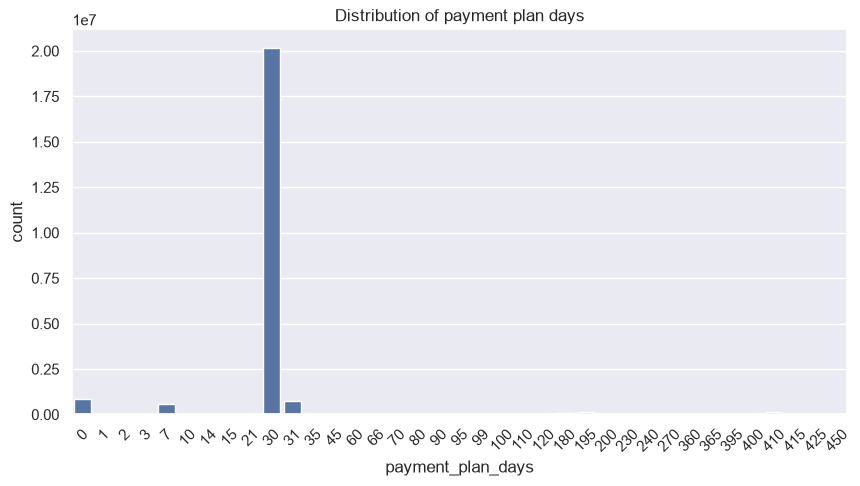

In [45]:
plt.figure(figsize=(10, 5))
sns.countplot(data=transaction, x=transaction['payment_plan_days'])
plt.title(f'Distribution of payment plan days')
plt.xticks(rotation=45)
plt.show()

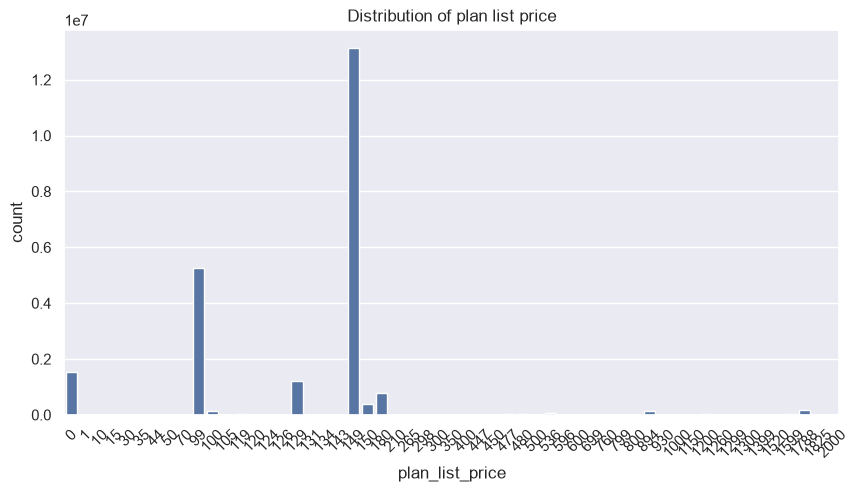

In [46]:
plt.figure(figsize=(10, 5))
sns.countplot(data=transaction, x=transaction['plan_list_price'])
plt.title(f'Distribution of plan list price')
plt.xticks(rotation=45)
plt.show()

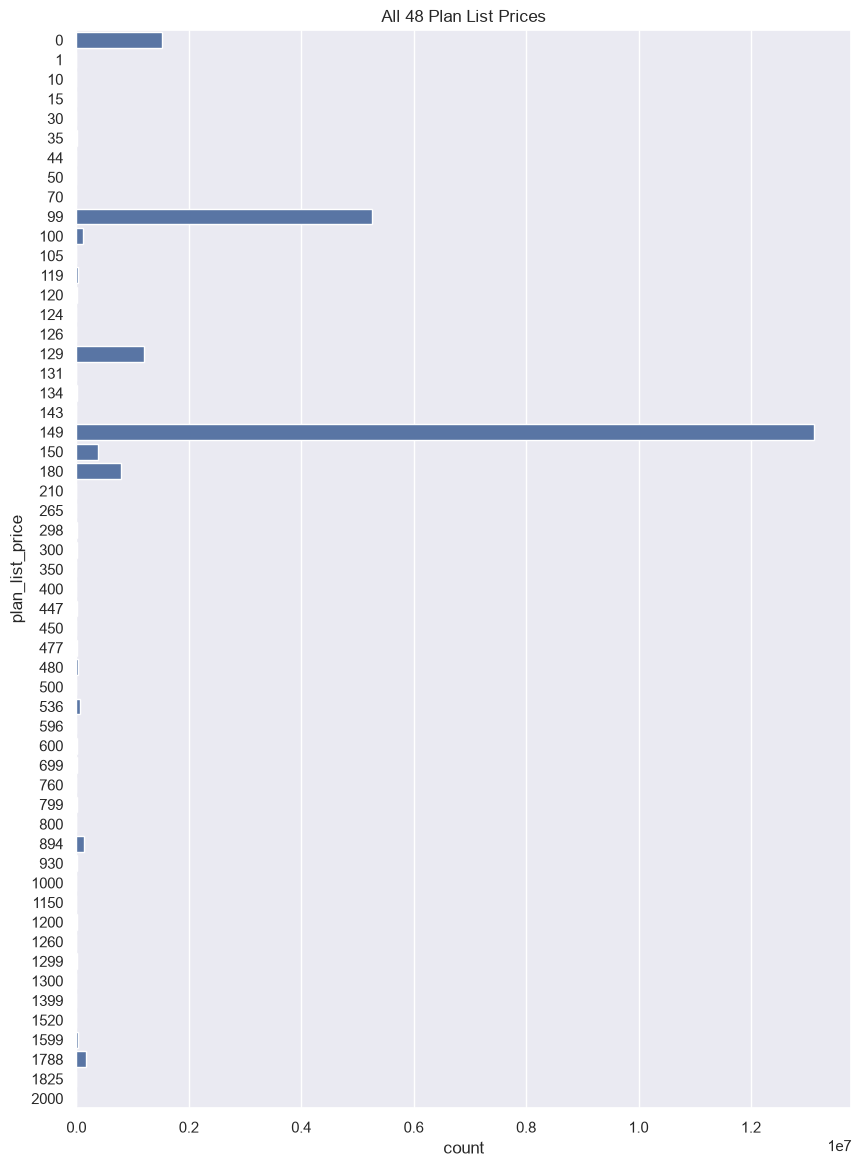

In [47]:
plt.figure(figsize=(10, 14)) # Taller height for 48 rows
sns.countplot(
    data=transaction, 
    y='plan_list_price', 
    order = sorted(transaction['plan_list_price'].unique())
)
plt.title('All 48 Plan List Prices')
plt.show()


In [ ]:
plt.figure(figsize=(10, 5))
sns.countplot(data=transaction, x=transaction['actual_amount_paid'])
plt.title(f'Distribution of actual amount paid')
plt.xticks(rotation=45)
plt.show()

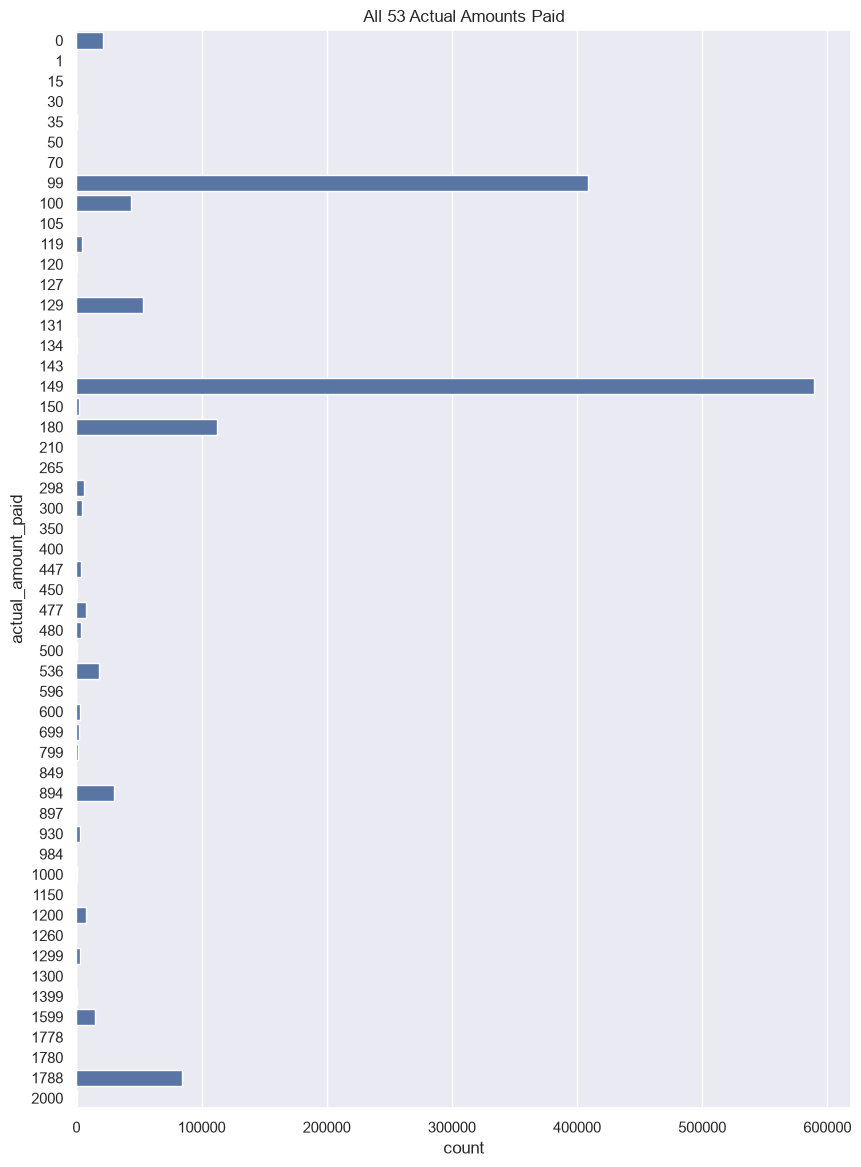

In [ ]:
plt.figure(figsize=(10, 14)) # Taller height for 53 rows
sns.countplot(
    data=transaction, 
    y='actual_amount_paid', 
    order = sorted(transaction['actual_amount_paid'].unique())
)
plt.title('All 53 Actual Amounts Paid')
plt.show()


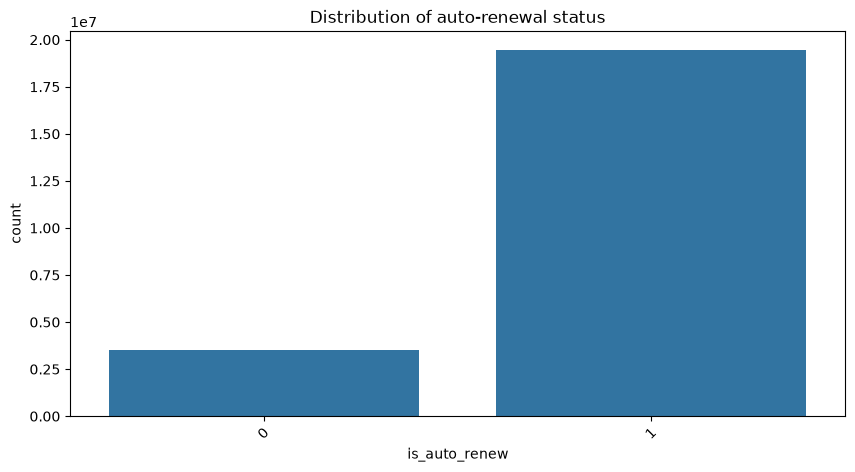

In [6]:
plt.figure(figsize=(10, 5))
sns.countplot(data=transaction, x=transaction['is_auto_renew'])
plt.title(f'Distribution of auto-renewal status')
plt.xticks(rotation=45)
plt.show()

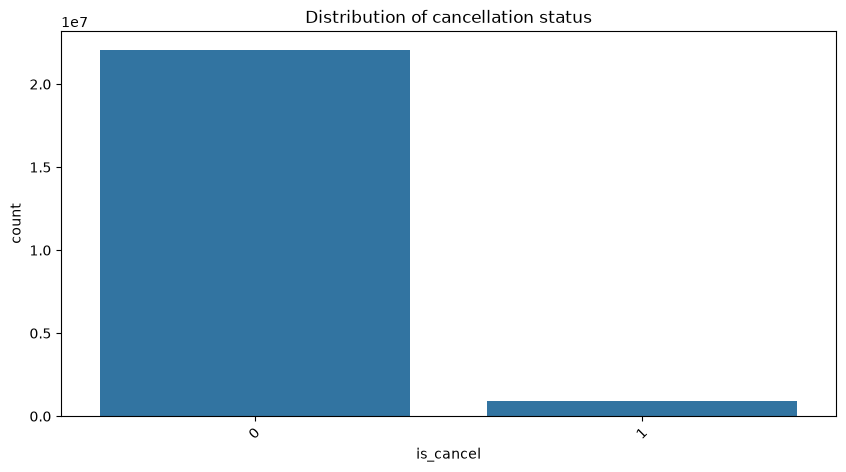

In [7]:
plt.figure(figsize=(10, 5))
sns.countplot(data=transaction, x=transaction['is_cancel'])
plt.title(f'Distribution of cancellation status')
plt.xticks(rotation=45)
plt.show()

In [8]:
transaction['transaction_date'] = transaction['transaction_date'].astype('str')
transaction['transaction_date'] = pd.to_datetime(transaction['transaction_date'], format='%Y%m%d', errors='coerce')

transaction['membership_expire_date'] = transaction['membership_expire_date'].astype('str')
transaction['membership_expire_date'] = pd.to_datetime(transaction['membership_expire_date'], format='%Y%m%d', errors='coerce')

In [9]:
transaction.info()

<class 'pandas.DataFrame'>
Index: 22975416 entries, 0 to 22978754
Data columns (total 9 columns):
 #   Column                  Dtype         
---  ------                  -----         
 0   msno                    str           
 1   payment_method_id       int64         
 2   payment_plan_days       int64         
 3   plan_list_price         int64         
 4   actual_amount_paid      int64         
 5   is_auto_renew           int64         
 6   transaction_date        datetime64[us]
 7   membership_expire_date  datetime64[us]
 8   is_cancel               int64         
dtypes: datetime64[us](2), int64(6), str(1)
memory usage: 2.7 GB


In [10]:
dtypes = {
    'msno': 'category',
    'payment_method_id': 'int8',
    'payment_plan_days': 'int16',
    'plan_list_price': 'int16',
    'actual_amount_paid': 'int16',
    'is_auto_renew': 'int8',
    'is_cancel': 'int8'
}

transaction = transaction.astype(dtypes)

In [11]:
transaction.info()

<class 'pandas.DataFrame'>
Index: 22975416 entries, 0 to 22978754
Data columns (total 9 columns):
 #   Column                  Dtype         
---  ------                  -----         
 0   msno                    category      
 1   payment_method_id       int8          
 2   payment_plan_days       int16         
 3   plan_list_price         int16         
 4   actual_amount_paid      int16         
 5   is_auto_renew           int8          
 6   transaction_date        datetime64[us]
 7   membership_expire_date  datetime64[us]
 8   is_cancel               int8          
dtypes: category(1), datetime64[us](2), int16(3), int8(3)
memory usage: 931.3 MB


In [12]:
#Number of transactions per user
transaction_per_user = transaction.groupby('msno').size().reset_index(name='transaction_count')

In [13]:
#Most frequent plan bought by users
most_frequent_plan = transaction.groupby(['msno'])['payment_plan_days'].agg(lambda x: x.value_counts().index[0]).reset_index(name='most_frequent_plan')

In [14]:
#Most frequent payment method per user
most_frequent_payment_method = transaction.groupby(['msno'])['payment_method_id'].agg(lambda x: x.value_counts().index[0]).reset_index(name='most_frequent_payment_method')

In [15]:
#Total amount paid by each user
total_amount_paid = transaction.groupby('msno')['actual_amount_paid'].sum().reset_index(name='total_amount_paid')

In [16]:
#How many times each user has auto-renewal enabled
auto_renewal_count = transaction.groupby('msno')['is_auto_renew'].sum().reset_index(name='auto_renewal')

In [17]:
#Number of cancellations per user
cancellation_count = transaction.groupby('msno')['is_cancel'].sum().reset_index(name='cancellation_count')

In [18]:
transaction['day'] = transaction['transaction_date'].dt.day_name()

In [19]:
transaction['month'] = transaction['transaction_date'].dt.month_name()

In [20]:
transaction['year'] = transaction['transaction_date'].dt.year

In [21]:
transaction['quarter'] = transaction['transaction_date'].dt.quarter

In [22]:
transaction['quarter_end'] = transaction['membership_expire_date'].dt.quarter

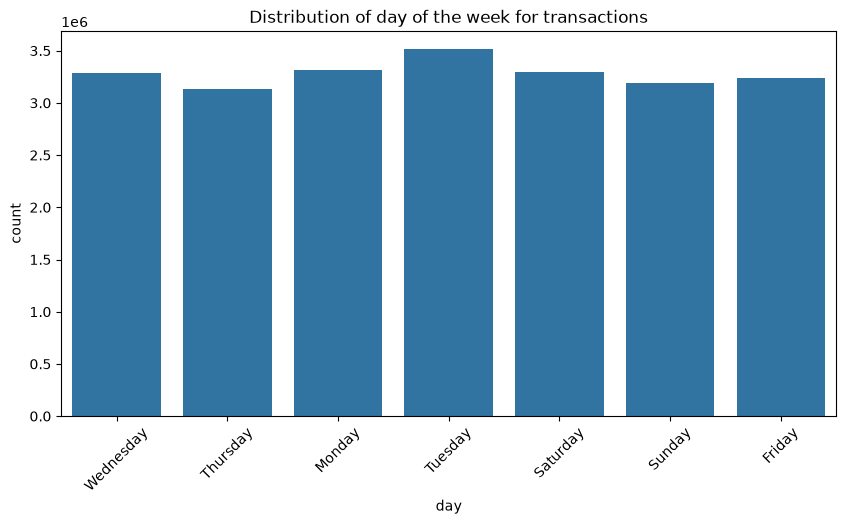

In [23]:
plt.figure(figsize=(10, 5))
sns.countplot(data=transaction, x=transaction['day'])
plt.title(f'Distribution of day of the week for transactions')
plt.xticks(rotation=45)
plt.show()

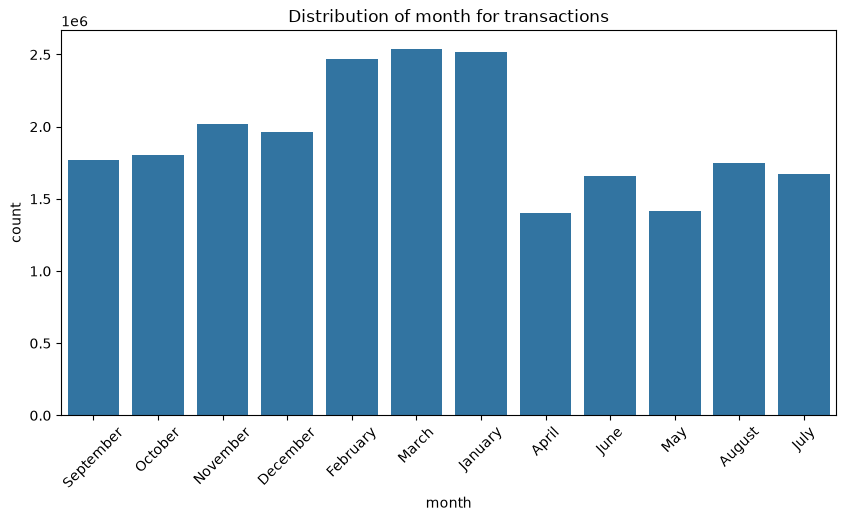

In [24]:
plt.figure(figsize=(10, 5))
sns.countplot(data=transaction, x=transaction['month'])
plt.title(f'Distribution of month for transactions')
plt.xticks(rotation=45)
plt.show()

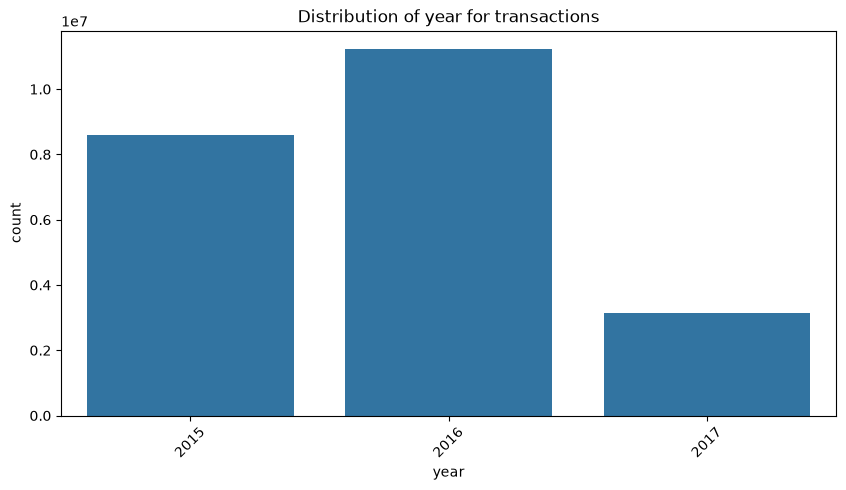

In [25]:
plt.figure(figsize=(10, 5))
sns.countplot(data=transaction, x=transaction['year'])
plt.title(f'Distribution of year for transactions')
plt.xticks(rotation=45)
plt.show()

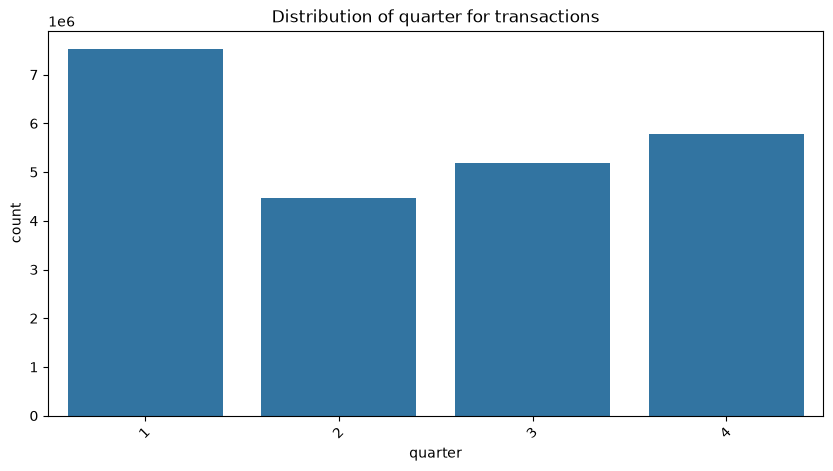

In [26]:
plt.figure(figsize=(10, 5))
sns.countplot(data=transaction, x=transaction['quarter'])
plt.title(f'Distribution of quarter for transactions')
plt.xticks(rotation=45)
plt.show()

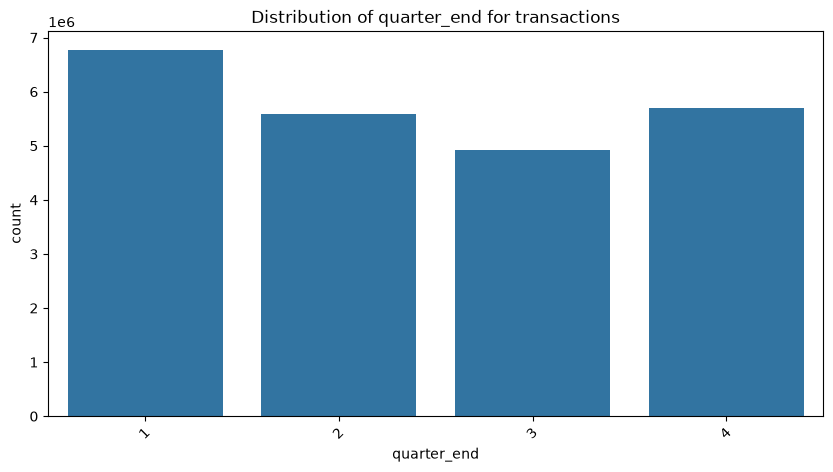

In [27]:
plt.figure(figsize=(10, 5))
sns.countplot(data=transaction, x=transaction['quarter_end'])
plt.title(f'Distribution of quarter_end for transactions')
plt.xticks(rotation=45)
plt.show()

In [28]:
quarter = transaction.groupby('msno')['quarter'].agg(lambda x: pd.Series.mode(x)[0]).reset_index()

In [29]:
datasets = ['transaction_per_user', 'most_frequent_plan', 'most_frequent_payment_method', 'total_amount_paid', 'auto_renewal_count', 'cancellation_count', 'quarter']
for i in datasets:
    print(f"{i} shape: {eval(i).shape}")

transaction_per_user shape: (2426143, 2)
most_frequent_plan shape: (2426143, 2)
most_frequent_payment_method shape: (2426143, 2)
total_amount_paid shape: (2426143, 2)
auto_renewal_count shape: (2426143, 2)
cancellation_count shape: (2426143, 2)
quarter shape: (2426143, 2)


In [30]:
transaction_updated = transaction_per_user.merge(most_frequent_plan, on='msno', how='left') \
    .merge(most_frequent_payment_method, on='msno', how='left') \
    .merge(total_amount_paid, on='msno', how='left') \
    .merge(auto_renewal_count, on='msno', how='left') \
    .merge(cancellation_count, on='msno', how='left') \
    .merge(quarter, on='msno', how='left')

In [31]:
transaction_updated.head()

,msno,transaction_count,most_frequent_plan,most_frequent_payment_method,total_amount_paid,auto_renewal,cancellation_count,quarter
0,+++FOrTS7ab3tIgIh8eWwX4FqRv8w/FoiOuyXsFvphY=,1,7,35,0,0,0,3
1,+++IZseRRiQS9aaSkH6cMYU6bGDcxUieAi/tH67sC5s=,2,410,38,3387,0,0,4
2,+++hVY1rZox/33YtvDgmKA2Frg/2qhkz12B9ylCvh8o=,5,30,41,495,5,0,1
3,+++l/EXNMLTijfLBa8p2TUVVVp2aFGSuUI/h7mLmthw=,21,30,39,3129,21,0,1
4,+++snpr7pmobhLKUgSHTv/mpkqgBT0tQJ0zQj6qKrqc=,27,30,41,4023,27,0,1


In [32]:
transaction_updated.shape

(2426143, 8)

In [ ]:
#Exporting the cleaned data as parquet file
transaction_updated.to_parquet("data/interim/transaction_cleaned.parquet", engine='pyarrow', index=False)